# Clasificador de imágenes: perros y gatos

Red convolucional para el proyecto 4Geeks `image-classifier-project-tutorial`.
El modelo es EfficientNet-B0 con `weights=None`, cabeza densa de 128 unidades y
una salida softmax de dos clases. Las fotos entran a 200×200 por generadores
de Keras (`ImageDataGenerator.flow_from_directory`).

La semilla fija es 42. No se leyó `solution.ipynb` ni `solution.es.ipynb`.
Los pesos se guardan en `models/` y no se versionan.

## Configuración

Esta celda fija la semilla, imprime las versiones y deja por escrito el
hardware y el contraste de la paleta usada en las figuras.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import numpy as np

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "pipeline.py").is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from pipeline import (
    BATCH_SIZE,
    DATASET_URL,
    EXTRACTED_TRAIN,
    IMAGE_SIZE,
    LEARNING_RATE,
    MAX_EPOCHS,
    MAX_EPOCHS_REASON,
    MAX_STEPS_PER_EPOCH,
    MODEL_PATH,
    PROCESSED,
    REPORTS,
    SEED,
    SUBSET_NOTE,
    TEMPLATE_COMMIT,
    build_callbacks,
    build_model,
    compile_model,
    ensure_fit_generator,
    file_sha256,
    first_n_images,
    flow_directory,
    hardware_note,
    make_generators,
    prepare_all,
    set_seed,
    steps_for,
    EpochTimer,
)
from plots import COLORS, apply_style, contrast_report

import keras
import tensorflow as tf

set_seed(SEED)
font_name = apply_style()
REPORTS.mkdir(parents=True, exist_ok=True)

print("python", sys.version.split()[0])
print("tensorflow", tf.__version__)
print("keras", keras.__version__)
print("seed", SEED)
print("image_size", IMAGE_SIZE)
print("batch_size", BATCH_SIZE)
print("max_epochs", MAX_EPOCHS)
print("max_epochs_reason", MAX_EPOCHS_REASON)
print("max_steps_per_epoch", MAX_STEPS_PER_EPOCH)
print("subset_note", SUBSET_NOTE)
print("learning_rate", LEARNING_RATE)
print("template_commit", TEMPLATE_COMMIT)
print("font", font_name)
print("contrast", json.dumps(contrast_report(), indent=2))
print("hardware", json.dumps(hardware_note(), indent=2))
print("dataset_url", DATASET_URL)

python 3.11.18
tensorflow 2.20.0
keras 3.15.1
seed 42
image_size (200, 200)
batch_size 16
max_epochs 8
max_epochs_reason El enunciado no fija el número de épocas. No hay GPU en esta VM. Una sonda de 8 pasos (batch 16) el 2026-11-06 midió 19,97 s en el primer paso y 0,406 s de media en los siete siguientes. Una época son 1250 pasos de entrenamiento (unas 8,5 min) más 157 de validación. El cupo es 8 épocas completas, con EarlyStopping(patience=2, monitor=val_loss). No se recorta el conjunto de imágenes.
max_steps_per_epoch None
subset_note No se usa un subconjunto: steps_per_epoch cubre todas las imágenes del split de entrenamiento y validation_steps cubre toda la validación.
learning_rate 0.0001
template_commit b49eff6673b76ba5b0003103e32f62a2eb9904a4
font Arimo
contrast {
  "ink_on_canvas": 15.44,
  "ink_on_surface": 16.4,
  "muted_on_canvas": 6.22,
  "on_action_on_action": 5.86,
  "info_on_surface": 7.9,
  "action_on_surface": 5.86,
  "success_on_surface": 7.14,
  "danger_on_surface":

2026-11-06 09:56:10.088906: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Paso 1. Carga del dataset

El zip oficial ya está en `data/raw/` (no se sube a git). Esta celda comprueba
el tamaño y el SHA-256, deja los JPEG etiquetados en
`data/raw/dogs-vs-cats/train/` y construye `train`, `val` y `test` con un
subdirectorio `cat` y otro `dog`.

El zip de Kaggle trae las etiquetas solo en `train/` (12 500 gatos y 12 500
perros). `sampleSubmission.csv` no tiene etiquetas, así que el test del
enunciado sale de un corte de esas 25 000 fotos: 10 000 / 1 250 / 1 250 por
clase, semilla 42 para gatos y 43 para perros. La validación no la pide el
enunciado con ese nombre; hace falta para que `EarlyStopping` vigile
`val_loss`.

In [2]:
summary = prepare_all(run_survey=True)
print("cats", summary["extracted"]["cats"])
print("dogs", summary["extracted"]["dogs"])
print("split", json.dumps(summary["split"]["counts"], indent=2))
print("zip_bytes", summary["zip"]["bytes"])
print("zip_sha256", summary["zip"]["sha256"])
print("size_survey", json.dumps(summary["size_survey"], indent=2))

cats 12500
dogs 12500
split {
  "cat": {
    "train": 10000,
    "val": 1250,
    "test": 1250
  },
  "dog": {
    "train": 10000,
    "val": 1250,
    "test": 1250
  }
}
zip_bytes 581507449
zip_sha256 8aabb6755161f0ec2a37f4fa9cff733c304824fe0a5cee652cf021e979d0937b
size_survey {
  "n": 25000,
  "modes": {
    "RGB": 25000
  },
  "unique_sizes": 8513,
  "width": {
    "min": 42,
    "max": 1050,
    "median": 447.0
  },
  "height": {
    "min": 32,
    "max": 768,
    "median": 374.0
  },
  "not_200x200": 24997
}


## Paso 2. Primeras nueve fotos

«Primeras» significa el orden numérico del nombre (`dog.0.jpg` … `dog.8.jpg`,
igual para gatos), no el orden del sistema de archivos. El título de cada
foto muestra el tamaño original. Todavía no están redimensionadas.

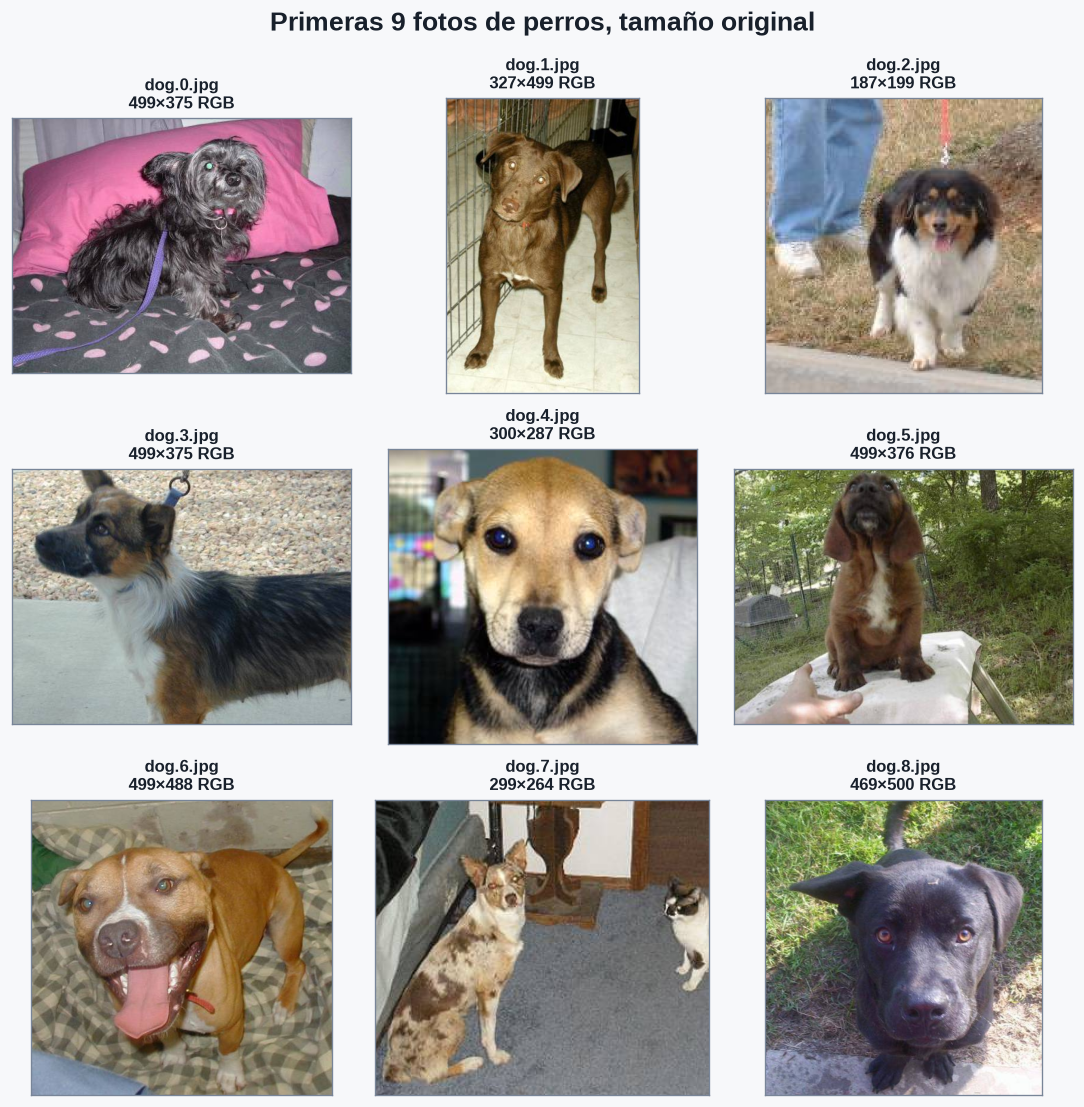

In [3]:
import matplotlib.pyplot as plt
from PIL import Image

def show_grid(paths, title, outfile):
    fig, axes = plt.subplots(3, 3, figsize=(9.2, 9.4))
    fig.suptitle(title, fontsize=16, fontweight="bold", color=COLORS["ink"])
    for ax, path in zip(axes.ravel(), paths):
        with Image.open(path) as image:
            rgb = image.convert("RGB")
            width, height = image.size
            mode = image.mode
            ax.imshow(np.asarray(rgb))
        ax.set_title(f"{path.name}\n{width}×{height} {mode}", fontsize=10, color=COLORS["ink"])
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color(COLORS["border"])
    fig.tight_layout()
    fig.savefig(outfile)
    plt.show()

dog_paths = first_n_images(EXTRACTED_TRAIN, "dog", 9)
show_grid(
    dog_paths,
    "Primeras 9 fotos de perros, tamaño original",
    REPORTS / "dogs_first9.png",
)

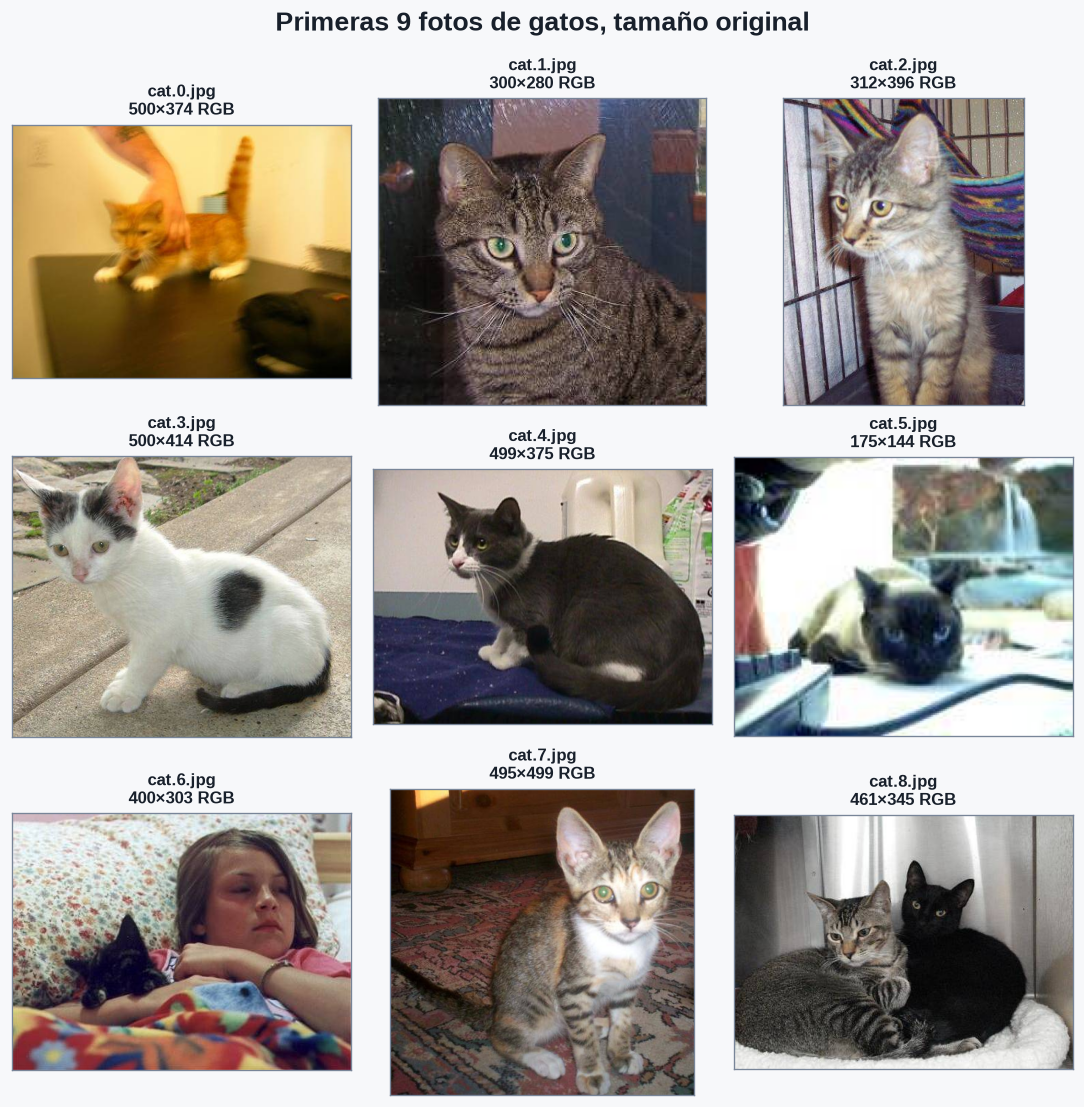

In [4]:
cat_paths = first_n_images(EXTRACTED_TRAIN, "cat", 9)
show_grid(
    cat_paths,
    "Primeras 9 fotos de gatos, tamaño original",
    REPORTS / "cats_first9.png",
)

## Generadores a 200×200

Hay unas 15 GiB de RAM física y un globo de memoria de unos 10 GiB. El tensor
float32 de 25 000×200×200×3 pesa unos 11,2 GiB, así que no cabe de forma
estable junto con el entrenamiento. El encargo pide la ruta de poca RAM:
`ImageDataGenerator` y `flow_from_directory`.

El fragmento de arquitectura del enunciado usa `(224, 224, 3)`. El párrafo
anterior exige 200×200. Se respeta 200×200 y la red se construye con
`input_shape=(200, 200, 3)`.

EfficientNet-B0 en Keras 3.15 divide entre 255 dentro del modelo. El
generador no vuelve a escalar: los lotes quedan en 0–255.

def flow_directory(directory: Path, image_size=IMAGE_SIZE, batch_size: int = BATCH_SIZE, seed: int = SEED, shuffle: bool = False):
    """Directory iterator. Pixels stay in 0–255.

    Keras 3 EfficientNetB0 rescales by 1/255 inside the network. A second
    rescale here would shrink the inputs again.
    """
    from tensorflow.keras.preprocessing.image import ImageDataGenerator

    datagen = ImageDataGenerator()
    return datagen.flow_from_directory(
        str(directory),
        target_size=image_size,
        batch_size=batch_size,
        class_mode="categorical",
        classes=["cat", "dog"],
        color_mode="rgb",
        shuffle=shuffle,
        seed=seed,
        interpolation="bilinear",
    )

def make_generators(processed_root: Path = PROCESSED, image_size=IMAGE_SIZE, batch_size: int = BATCH_SIZE, seed: int = SEED):
    trdata = flow_directory(processed_root / "train", image_size, batch_size, seed, shuffle=True)
    tsdata = flow_directory(processed_root / "test", 

Found 2500 images belonging to 2 classes.


Found 2500 images belonging to 2 classes.


trdata DirectoryIterator 20000 (200, 200) {'cat': 0, 'dog': 1}
tsdata 2500 (200, 200) shuffle False
valdata 2500 (200, 200)
batch (16, 200, 200, 3) (16, 2) min 0.0 max 255.0


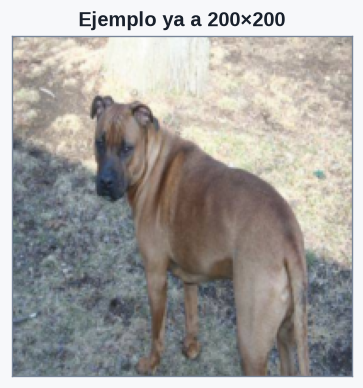

In [5]:
import inspect

print(inspect.getsource(flow_directory))
print(inspect.getsource(make_generators))
trdata, tsdata, valdata = make_generators(
    PROCESSED, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, seed=SEED
)
print("trdata", type(trdata).__name__, trdata.samples, trdata.target_size, trdata.class_indices)
print("tsdata", tsdata.samples, tsdata.target_size, "shuffle", tsdata.shuffle)
print("valdata", valdata.samples, valdata.target_size)
preview_x, preview_y = next(trdata)
print(
    "batch", preview_x.shape, preview_y.shape,
    "min", float(preview_x.min()), "max", float(preview_x.max()),
)
fig, ax = plt.subplots(figsize=(3.4, 3.4))
ax.imshow(preview_x[0].astype("uint8"))
ax.set_title(f"Ejemplo ya a {preview_x.shape[1]}×{preview_x.shape[2]}", fontsize=12)
ax.set_xticks([])
ax.set_yticks([])
fig.tight_layout()
fig.savefig(REPORTS / "resized_sample.png")
plt.show()

## Paso 3. Red

Misma pila que el enunciado: EfficientNet-B0 sin cabeza ni pesos de ImageNet,
pooling global, densa de 128 con ReLU y densa de 2 con softmax. El optimizador
es Adam a 1e-4 con `clipnorm=1`, porque el enunciado no fija el optimizador y
una red desde cero en CPU se inestabiliza con un paso demasiado grande.

In [6]:
print(inspect.getsource(build_model))
print(inspect.getsource(compile_model))
model = build_model(input_shape=(200, 200, 3))
compile_model(model, learning_rate=LEARNING_RATE)
model.summary()
probe = model(preview_x[:2], training=False).numpy()
print("probe_softmax", probe)
print("probe_finite", bool(np.isfinite(probe).all()))

def build_model(input_shape=(200, 200, 3)):
    from tensorflow.keras.applications import EfficientNetB0
    from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
    from tensorflow.keras.models import Sequential

    model = Sequential(name="dogs_vs_cats")
    model.add(
        EfficientNetB0(
            include_top=False,
            weights=None,
            input_shape=input_shape,
        )
    )
    model.add(GlobalAveragePooling2D())
    model.add(Dense(units=128, activation="relu"))
    model.add(Dense(units=2, activation="softmax"))
    return model

def compile_model(model, learning_rate: float = LEARNING_RATE):
    from tensorflow.keras.optimizers import Adam

    model.compile(
        optimizer=Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False,
    )
    return model



Model: "dogs_vs_cats"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 4,171,774 (15.91 MB)

 Non-trainable params: 42,023 (164.16 KB)

probe_softmax [[0.4999947 0.5000053]
 [0.4999948 0.5000052]]
probe_finite True


## Paso 4. ModelCheckpoint, EarlyStopping y fit_generator

Keras 3.15 ya no trae `Model.fit_generator`. `ensure_fit_generator` lo
restituye como envoltorio de `Model.fit` (la API vigente, que acepta
generadores y callbacks). La llamada del notebook sigue siendo
`model.fit_generator(...)`.

`workers` se acepta en esa llamada por compatibilidad con la firma antigua.
`Model.fit` de Keras 3 no tiene ese argumento, así que el envoltorio lo
descarta y el generador corre en el proceso principal.

Los generadores se crean de nuevo para que el lote de previsualización no
desplace el recorrido del entrenamiento.

In [7]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

fit_kind = ensure_fit_generator()
print("fit_generator_impl", fit_kind)
print(inspect.getsource(build_callbacks))
print(inspect.getsource(ensure_fit_generator))

checkpoint, early_stopping, csv_logger = build_callbacks(
    MODEL_PATH,
    patience=2,
    csv_path=REPORTS / "training_log.csv",
)
assert isinstance(checkpoint, ModelCheckpoint)
assert isinstance(early_stopping, EarlyStopping)

trdata, tsdata, valdata = make_generators(
    PROCESSED, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, seed=SEED
)
steps_per_epoch = steps_for(trdata)
print("steps_per_epoch", steps_per_epoch, "len_trdata", len(trdata))
print("val_steps", len(valdata), "val_samples", valdata.samples)
print("epochs", MAX_EPOCHS)
print(MAX_EPOCHS_REASON)
print(SUBSET_NOTE)

timer = EpochTimer()
history = model.fit_generator(
    trdata,
    steps_per_epoch=steps_per_epoch,
    epochs=MAX_EPOCHS,
    validation_data=valdata,
    validation_steps=len(valdata),
    callbacks=[checkpoint, early_stopping, csv_logger, timer.callback],
    verbose=2,
    shuffle=False,
)
history_payload = {
    key: [float(value) for value in values] for key, values in history.history.items()
}
history_payload["epoch_seconds"] = list(timer.callback.epoch_seconds)
history_payload["stopped_epoch"] = int(getattr(early_stopping, "stopped_epoch", 0) or 0)
(REPORTS / "history.json").write_text(json.dumps(history_payload, indent=2))
print(json.dumps(history_payload, indent=2))

fit_generator_impl wrapper-around-fit
def build_callbacks(model_path: Path = MODEL_PATH, patience: int = EARLY_STOPPING_PATIENCE, csv_path: Path | None = None):
    from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint

    model_path.parent.mkdir(parents=True, exist_ok=True)
    checkpoint = ModelCheckpoint(
        filepath=str(model_path),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1,
    )
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=patience,
        mode="min",
        restore_best_weights=True,
        verbose=1,
    )
    logger = None
    if csv_path is not None:
        csv_path.parent.mkdir(parents=True, exist_ok=True)
        logger = CSVLogger(str(csv_path), append=False)
    return checkpoint, early_stopping, logger

def ensure_fit_generator() -> str:
    """Return which implementation ``fit_generator`` will call."""
    import inspect

    import keras

    if

Found 2500 images belonging to 2 classes.


Found 2500 images belonging to 2 classes.


steps_per_epoch 1250 len_trdata 1250
val_steps 157 val_samples 2500
epochs 8
El enunciado no fija el número de épocas. No hay GPU en esta VM. Una sonda de 8 pasos (batch 16) el 2026-11-06 midió 19,97 s en el primer paso y 0,406 s de media en los siete siguientes. Una época son 1250 pasos de entrenamiento (unas 8,5 min) más 157 de validación. El cupo es 8 épocas completas, con EarlyStopping(patience=2, monitor=val_loss). No se recorta el conjunto de imágenes.
No se usa un subconjunto: steps_per_epoch cubre todas las imágenes del split de entrenamiento y validation_steps cubre toda la validación.


Epoch 1/8



Epoch 1: val_loss improved from None to 0.61877, saving model to /workspace/models/dogs_vs_cats_best.keras


... (27 outputs left out)

1250/1250 - 599s - 479ms/step - accuracy: 0.8758 - loss: 0.2904 - val_accuracy: 0.7616 - val_loss: 0.5825


Epoch 8: early stopping


Restoring model weights from the end of the best epoch: 6.


{
  "accuracy": [
    0.6053000092506409,
    0.6629499793052673,
    0.7091000080108643,
    0.7524499893188477,
    0.7881500124931335,
    0.8205500245094299,
    0.8554499745368958,
    0.8758000135421753
  ],
  "loss": [
    0.6688210964202881,
    0.6155732274055481,
    0.5598852038383484,
    0.5046384334564209,
    0.4518870711326599,
    0.3979943096637726,
    0.33480584621429443,
    0.29036498069763184
  ],
  "val_accuracy": [
    0.6660000085830688,
    0.6972000002861023,
    0.7228000164031982,
    0.758400022983551,
    0.7847999930381775,
    0.782800018787384,
    0.7907999753952026,
    0.7616000175476074
  ],
  "val_loss": [
    0.6187682151794434,
    0.5808308124542236,
    0.5524910688400269,
    0.4932939410209656,
    0.4879136085510254,
    0.4656011164188385,
    0.5103081464767456,
    0.5824826955795288
  ],
  "epoch_seconds": [
    554.719,
    517.558,
    540.034,
    518.796,
    524.756,
    534.66,
    526.984,
    567.826
  ],
  "stopped_epoch": 7
}

## Curvas

Línea continua azul (`#204EA0`) para entrenamiento y línea discontinua
granate (`#B53A17`) para validación. El texto va en `#18202B` sobre fondo
`#F7F8FA`. No depende solo del color: cada serie tiene marca y estilo propios.

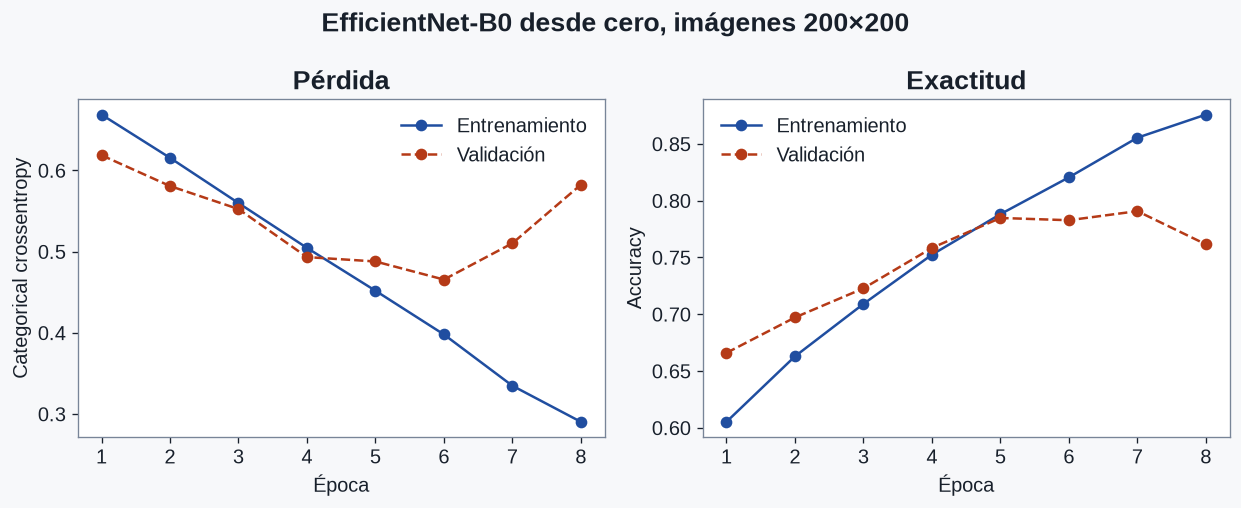

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.3))
epochs = list(range(1, len(history_payload["loss"]) + 1))
axes[0].plot(epochs, history_payload["loss"], color=COLORS["info"], marker="o", label="Entrenamiento")
axes[0].plot(
    epochs, history_payload["val_loss"], color=COLORS["action"], marker="o", linestyle="--", label="Validación"
)
axes[0].set_title("Pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Categorical crossentropy")
axes[0].legend()
axes[1].plot(epochs, history_payload["accuracy"], color=COLORS["info"], marker="o", label="Entrenamiento")
axes[1].plot(
    epochs,
    history_payload["val_accuracy"],
    color=COLORS["action"],
    marker="o",
    linestyle="--",
    label="Validación",
)
axes[1].set_title("Exactitud")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
for ax in axes:
    ax.set_xticks(epochs)
fig.suptitle("EfficientNet-B0 desde cero, imágenes 200×200", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(REPORTS / "training_curves.png")
plt.show()

## Evaluación reproducible

Esta celda no reutiliza el objeto `model` del entrenamiento. Vuelve a fijar
la semilla, reconstruye `tsdata` con `shuffle=False` y carga el checkpoint
de menor `val_loss` desde `models/dogs_vs_cats_best.keras`.

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import load_model

set_seed(SEED)
best = load_model(MODEL_PATH)
_, tsdata, _ = make_generators(
    PROCESSED, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, seed=SEED
)
tsdata.reset()
eval_loss, eval_acc = best.evaluate(tsdata, steps=len(tsdata), verbose=1)
tsdata.reset()
probs = np.asarray(best.predict(tsdata, steps=len(tsdata), verbose=1))
n = int(tsdata.samples)
if len(probs) < n:
    raise RuntimeError(f"predict devolvió {len(probs)} filas para {n} fotos")
probs = probs[:n]
y_true = np.asarray(tsdata.classes)[:n]
y_pred = probs.argmax(axis=1)
filenames = list(tsdata.filenames)[:n]
labels = ["cat", "dog"]
text_report = classification_report(y_true, y_pred, target_names=labels, digits=4, zero_division=0)
report = classification_report(
    y_true, y_pred, target_names=labels, digits=4, zero_division=0, output_dict=True
)
matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
hits = int(np.sum(y_true == y_pred))
errors = int(np.sum(y_true != y_pred))
evaluation = {
    "seed": SEED,
    "shuffle_test": False,
    "model_path": str(MODEL_PATH.relative_to(ROOT)),
    "model_bytes": MODEL_PATH.stat().st_size,
    "model_sha256": file_sha256(MODEL_PATH),
    "test_samples": n,
    "prediction_rows": int(len(probs)),
    "loss": float(eval_loss),
    "accuracy": float(eval_acc),
    "confusion_matrix_labels": labels,
    "confusion_matrix": matrix.tolist(),
    "classification_report": report,
    "hits": hits,
    "errors": errors,
}
(REPORTS / "evaluation.json").write_text(json.dumps(evaluation, indent=2))
(REPORTS / "evaluation.txt").write_text(
    text_report
    + "\n"
    + json.dumps({key: evaluation[key] for key in ("loss", "accuracy", "hits", "errors", "test_samples", "model_bytes", "model_sha256")}, indent=2)
    + "\n"
)
print(text_report)
print("loss", float(eval_loss), "accuracy", float(eval_acc), "hits", hits, "errors", errors)

Found 20000 images belonging to 2 classes.


Found 2500 images belonging to 2 classes.


Found 2500 images belonging to 2 classes.


  1/157 ━━━━━━━━━━━━━━━━━━━━ 7:16 3s/step - accuracy: 0.8750 - loss: 0.3786

  2/157 ━━━━━━━━━━━━━━━━━━━━ 13s 85ms/step - accuracy: 0.7500 - loss: 0.5672

  3/157 ━━━━━━━━━━━━━━━━━━━━ 12s 84ms/step - accuracy: 0.7500 - loss: 0.5891

... (309 outputs left out)

156/157 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 14s 83ms/step


              precision    recall  f1-score   support

         cat     0.8042    0.7296    0.7651      1250
         dog     0.7526    0.8224    0.7859      1250

    accuracy                         0.7760      2500
   macro avg     0.7784    0.7760    0.7755      2500
weighted avg     0.7784    0.7760    0.7755      2500

loss 0.4657174348831177 accuracy 0.7760000228881836 hits 1940 errors 560


## Matriz de confusión

Filas: etiqueta real. Columnas: predicción. Orden: cat, dog.

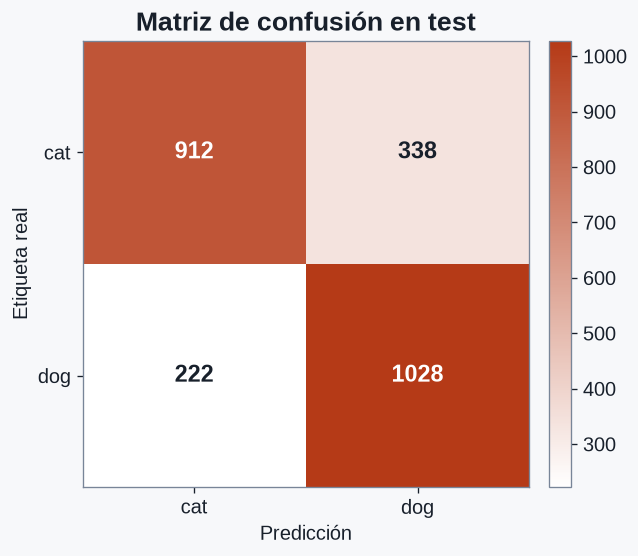

In [10]:
from matplotlib.colors import LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(5.4, 4.8))
cmap = LinearSegmentedColormap.from_list("signal_heat", [COLORS["surface"], COLORS["action"]])
image = ax.imshow(matrix, cmap=cmap)
ax.set_xticks([0, 1], labels)
ax.set_yticks([0, 1], labels)
ax.set_xlabel("Predicción")
ax.set_ylabel("Etiqueta real")
ax.set_title("Matriz de confusión en test")
peak = float(matrix.max()) if matrix.max() else 1.0
for row in range(2):
    for col in range(2):
        value = int(matrix[row, col])
        text_color = COLORS["on_action"] if value > peak / 2 else COLORS["ink"]
        ax.text(col, row, str(value), ha="center", va="center", color=text_color, fontsize=14, fontweight="bold")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(REPORTS / "confusion_matrix.png")
plt.show()

## Muestra de aciertos y errores

Se toman los primeros seis aciertos y los primeros seis errores en el orden
del generador de test (`shuffle=False`, semilla 42). No es un sorteo nuevo.
Si faltara uno de los dos grupos, la celda lo diría y no rellenaría la figura
con fotos inventadas.

hits_available 1940 errors_available 560


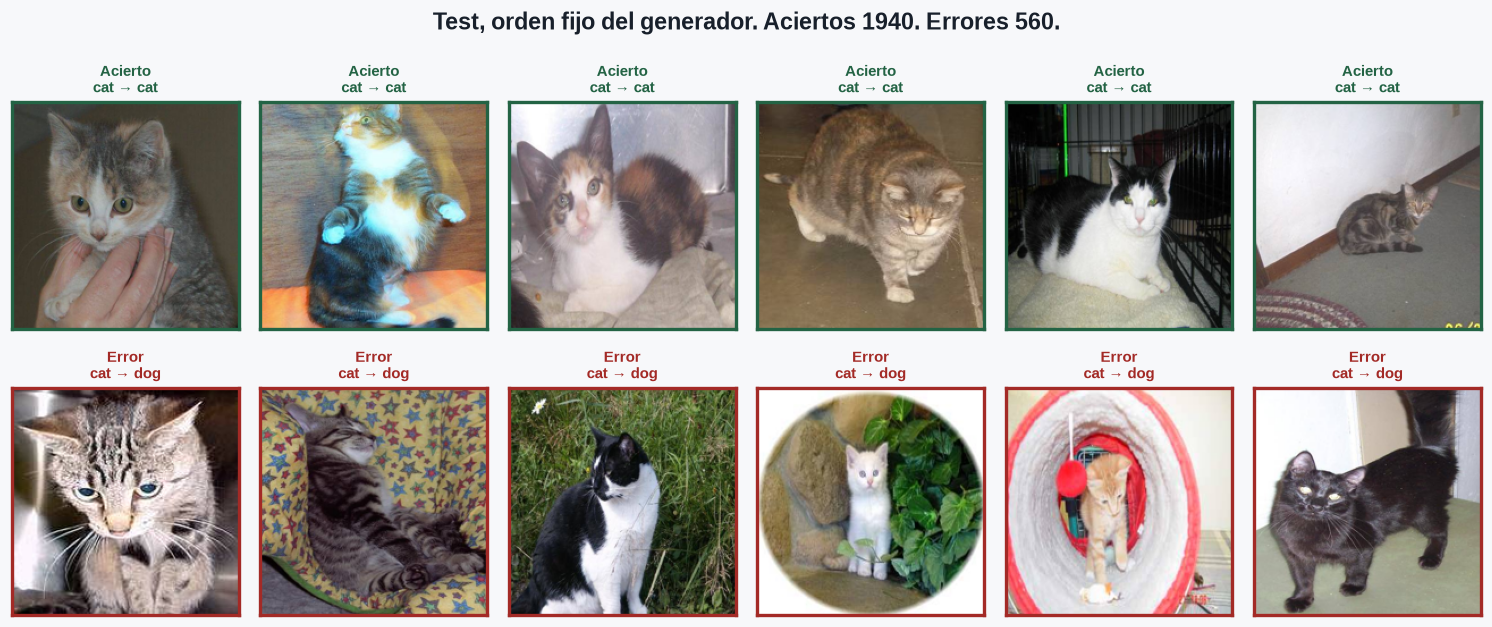

In [11]:
hit_idx = np.flatnonzero(y_true == y_pred)
miss_idx = np.flatnonzero(y_true != y_pred)
print("hits_available", int(hit_idx.size), "errors_available", int(miss_idx.size))
chosen = {"Aciertos": hit_idx[:6], "Errores": miss_idx[:6]}
row_color = {"Aciertos": COLORS["success"], "Errores": COLORS["danger"]}

fig, axes = plt.subplots(2, 6, figsize=(12.6, 5.6))
for row, (label, indexes) in enumerate(chosen.items()):
    for col in range(6):
        ax = axes[row, col]
        ax.set_xticks([])
        ax.set_yticks([])
        if col >= len(indexes):
            ax.set_facecolor(COLORS["subtle"])
            ax.set_title("Sin caso", fontsize=9, color=COLORS["muted"])
            continue
        index = int(indexes[col])
        path = PROCESSED / "test" / filenames[index]
        with Image.open(path) as image:
            rgb = image.convert("RGB").resize((200, 200))
            ax.imshow(np.asarray(rgb))
        true_name = labels[int(y_true[index])]
        pred_name = labels[int(y_pred[index])]
        short_label = {"Aciertos": "Acierto", "Errores": "Error"}[label]
        ax.set_title(f"{short_label}\n{true_name} → {pred_name}", fontsize=9, color=row_color[label])
        for spine in ax.spines.values():
            spine.set_color(row_color[label])
            spine.set_linewidth(2)
fig.suptitle(
    f"Test, orden fijo del generador. Aciertos {int(hit_idx.size)}. Errores {int(miss_idx.size)}.",
    fontsize=14,
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(REPORTS / "sample_predictions.png")
plt.show()

## Paso 5. Modelo guardado

`ModelCheckpoint` escribe el mejor modelo en `models/dogs_vs_cats_best.keras`.
`git check-ignore` confirma que ese archivo no entra en el repositorio.

In [12]:
print("model_path", MODEL_PATH)
print("model_bytes", MODEL_PATH.stat().st_size)
print("model_sha256", evaluation["model_sha256"])
ignored = subprocess.run(
    ["git", "check-ignore", "-v", "models/dogs_vs_cats_best.keras"],
    cwd=ROOT,
    capture_output=True,
    text=True,
    check=False,
)
print(ignored.stdout.strip() or ignored.stderr.strip())
if ignored.returncode != 0:
    raise RuntimeError("el checkpoint no está cubierto por .gitignore")

manifest = {
    "seed": SEED,
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "max_epochs_reason": MAX_EPOCHS_REASON,
    "max_steps_per_epoch": MAX_STEPS_PER_EPOCH,
    "subset_note": SUBSET_NOTE,
    "steps_per_epoch": steps_per_epoch,
    "learning_rate": LEARNING_RATE,
    "weights": None,
    "input_shape": [200, 200, 3],
    "snippet_input_shape_not_used": [224, 224, 3],
    "fit_generator_impl": fit_kind,
    "early_stopping_patience": 2,
    "early_stopping_monitor": "val_loss",
    "stopped_epoch": history_payload["stopped_epoch"],
    "epoch_seconds": history_payload["epoch_seconds"],
    "history": {key: history_payload[key] for key in history_payload if key.startswith(("loss", "accuracy", "val_"))},
    "test_loss": evaluation["loss"],
    "test_accuracy": evaluation["accuracy"],
    "test_hits": evaluation["hits"],
    "test_errors": evaluation["errors"],
    "test_samples": evaluation["test_samples"],
    "model_bytes": evaluation["model_bytes"],
    "model_sha256": evaluation["model_sha256"],
    "font": font_name,
    "contrast": contrast_report(),
    "hardware": hardware_note(),
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "python": sys.version.split()[0],
    "template_commit": TEMPLATE_COMMIT,
    "dataset_url": DATASET_URL,
}
(REPORTS / "run_manifest.json").write_text(json.dumps(manifest, indent=2))
print(json.dumps({key: manifest[key] for key in ("test_accuracy", "test_loss", "epoch_seconds", "stopped_epoch", "model_bytes")}, indent=2))

model_path /workspace/models/dogs_vs_cats_best.keras
model_bytes 51235467
model_sha256 056311485172c06ee84a3a00a24bb0b3ee57a00939af5e52c222943f98c8df95
.gitignore:19:*.keras	models/dogs_vs_cats_best.keras
{
  "test_accuracy": 0.7760000228881836,
  "test_loss": 0.4657174348831177,
  "epoch_seconds": [
    554.719,
    517.558,
    540.034,
    518.796,
    524.756,
    534.66,
    526.984,
    567.826
  ],
  "stopped_epoch": 7,
  "model_bytes": 51235467
}
